# Assignment 1 - Building a Vision Model with Keras

In this assignment, you will build a simple vision model using Keras. The goal is to classify images from the Fashion MNIST dataset, which contains images of clothing items.

You will:
1. Load and inspect the Fashion MNIST dataset.
2. Run a simple baseline model to establish a performance benchmark.
3. Build and evaluate a simple CNN model, choosing appropriate loss and metrics.
4. Design and run controlled experiments on one hyperparameter (e.g., number of filters, kernel size, etc.) and one regularization technique (e.g., dropout, L2 regularization).
5. Analyze the results and visualize the model's performance.

# 1. Loading and Inspecting the Dataset

Fashion MNIST is a dataset of grayscale images of clothing items, with 10 classes. Each image is 28x28 pixels, like the MNIST dataset of handwritten digits. Keras provides a convenient way to load this dataset. 

In this section, you should:

- [ ] Inspect the shapes of the training and test sets to confirm their size and structure.
- [ ] Convert the labels to one-hot encoded format if necessary. (There is a utility function in Keras for this.)
- [ ] Visualize a few images from the dataset to understand what the data looks like.

In [4]:
from tensorflow.keras.datasets import fashion_mnist
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Normalize the pixel values to be between 0 and 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Classes in the Fashion MNIST dataset
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

In [5]:
# Inspect the shapes of the datasets
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

# Convert labels to one-hot encoding
from tensorflow.keras.utils import to_categorical

y_train_encoded = to_categorical(y_train, 10)
y_test_encoded = to_categorical(y_test, 10)



(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


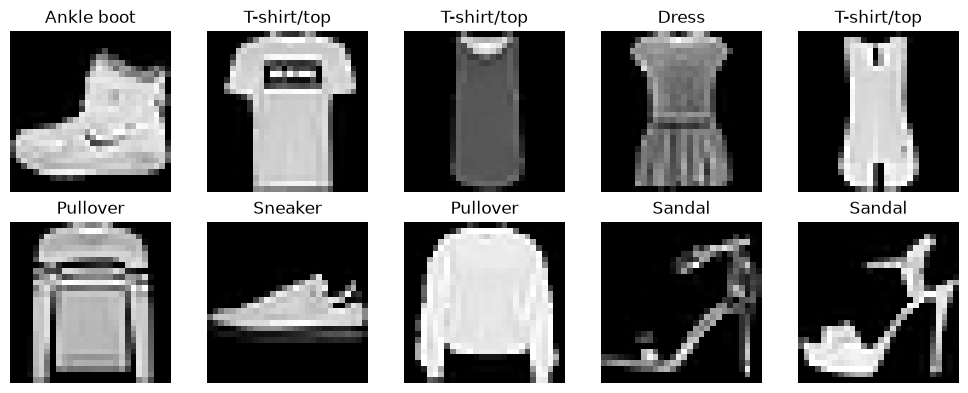

In [6]:
import matplotlib.pyplot as plt
# Verify the data looks as expected

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()


Reflection: Does the data look as expected? How is the quality of the images? Are there any issues with the dataset that you notice?

The images look as expected, most items are recognizable. Some look similar, which could make them difficult to classify

# 2. Baseline Model

In this section, you will create a linear regression model as a baseline. This model will not use any convolutional layers, but it will help you understand the performance of a simple model on this dataset.
You should:
- [ ] Create a simple linear regression model using Keras.
- [ ] Compile the model with an appropriate loss function and optimizer.
- [ ] Train the model on the training set and evaluate it on the test set.

A linear regression model can be created using the `Sequential` API in Keras. Using a single `Dense` layer with no activation function is equivalent to a simple linear regression model. Make sure that the number of units in the output layer matches the number of classes in the dataset.

Note that for this step, we will need to use `Flatten` to convert the 2D images into 1D vectors before passing them to the model. Put a `Flatten()` layer as the first layer in your model so that the 2D image data can be flattened into 1D vectors.

In [10]:
from keras.models import Sequential
from keras.layers import Dense, Flatten

# Create a simple linear regression model
model = Sequential()
model.add(Flatten(input_shape=(28, 28)))
model.add(Dense(10))

# Compile the model using model.compile()
model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["accuracy"]
)

# Train the model with model.fit()
model.fit(X_train, y_train_encoded, epochs=4, batch_size=128)

# Evaluate the model with model.evaluate()
baseline_loss, baseline_accuracy = model.evaluate(
    X_test, y_test_encoded
)

print("Baseline accuracy:", baseline_accuracy)

Epoch 1/4
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 485us/step - accuracy: 0.6919 - loss: 0.0687
Epoch 2/4
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 467us/step - accuracy: 0.7973 - loss: 0.0437
Epoch 3/4
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 535us/step - accuracy: 0.8092 - loss: 0.0403
Epoch 4/4
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 560us/step - accuracy: 0.8149 - loss: 0.0389
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 336us/step - accuracy: 0.7980 - loss: 0.0401
Baseline accuracy: 0.7979999780654907


Reflection: What is the performance of the baseline model? How does it compare to what you expected? Why do you think the performance is at this level?

The baseline model achieved almost 80% test accuracy. This was a reasonable result for a simple model, but similar clothing items were probably harder to distinguish.

# 3. Building and Evaluating a Simple CNN Model

In this section, you will build a simple Convolutional Neural Network (CNN) model using Keras. A convolutional neural network is a type of deep learning model that is particularly effective for image classification tasks. Unlike the basic neural networks we have built in the labs, CNNs can accept images as input without needing to flatten them into vectors.

You should:
- [ ] Build a simple CNN model with at least one convolutional layer (to learn spatial hierarchies in images) and one fully connected layer (to make predictions).
- [ ] Compile the model with an appropriate loss function and metrics for a multi-class classification problem.
- [ ] Train the model on the training set and evaluate it on the test set.

Convolutional layers are designed to accept inputs with three dimensions: height, width and channels (e.g., RGB for color images). For grayscale images like those in Fashion MNIST, the input shape will be (28, 28, 1).

When you progress from the convolutional layers to the fully connected layers, you will need to flatten the output of the convolutional layers. This can be done using the `Flatten` layer in Keras, which doesn't require any parameters.

In [11]:
from keras.layers import Conv2D

# Reshape the data to include the channel dimension
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Create a simple CNN model
model = Sequential()
model.add(Conv2D(32, (3, 3), activation="relu",
                 input_shape=(28, 28, 1)))
model.add(Flatten())
model.add(Dense(64, activation="relu"))
model.add(Dense(10, activation="softmax"))

# Compile the model
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Train the model
model.fit(X_train, y_train_encoded, epochs=4, batch_size=128)

# Evaluate the model
cnn_loss, cnn_accuracy = model.evaluate(X_test, y_test_encoded)

print("CNN accuracy:", cnn_accuracy)
print("Improvement in percentage points:",
      (cnn_accuracy - baseline_accuracy) * 100)

Epoch 1/4
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8426 - loss: 0.4514
Epoch 2/4
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8936 - loss: 0.2965
Epoch 3/4
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9093 - loss: 0.2525
Epoch 4/4
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9201 - loss: 0.2200
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 784us/step - accuracy: 0.8980 - loss: 0.2821
CNN accuracy: 0.8980000019073486
Improvement in percentage points: 10.000002384185791


Reflection: Did the CNN model perform better than the baseline model? If so, by how much? What do you think contributed to this improvement?

The CNN achieved almost 90% test accuracy, which was 10 percentage points higher than the baseline. Its convolutional layer helped it learn edges and shapes, making it better at recognizing clothing items

# 3. Designing and Running Controlled Experiments

In this section, you will design and run controlled experiments to improve the model's performance. You will focus on one hyperparameter and one regularization technique.
You should:
- [ ] Choose one hyperparameter to experiment with (e.g., number of filters, kernel size, number of layers, etc.) and one regularization technique (e.g., dropout, L2 regularization). For your hyperparameter, you should choose at least three different values to test (but there is no upper limit). For your regularization technique, simply test the presence or absence of the technique.
- [ ] Run experiments by modifying the model architecture or hyperparameters, and evaluate the performance of each model on the test set.
- [ ] Record the results of your experiments, including the test accuracy and any other relevant metrics.
- [ ] Visualize the results of your experiments using plots or tables to compare the performance of different models.

The best way to run your experiments is to create a `for` loop that iterates over a range of values for the hyperparameter you are testing. For example, if you are testing different numbers of filters, you can create a loop that runs the model with 32, 64, and 128 filters. Within the loop, you can compile and train the model, then evaluate it on the test set. After each iteration, you can store the results in a list or a dictionary for later analysis.

Note: It's critical that you re-initialize the model (by creating a new instance of the model) before each experiment. If you don't, the model will retain the weights from the previous experiment, which can lead to misleading results.

Filters: 16
Test accuracy: 0.8971999883651733
Test loss: 0.28176888823509216
Filters: 32
Test accuracy: 0.8974000215530396
Test loss: 0.2820599675178528
Filters: 64
Test accuracy: 0.9031000137329102
Test loss: 0.26970410346984863


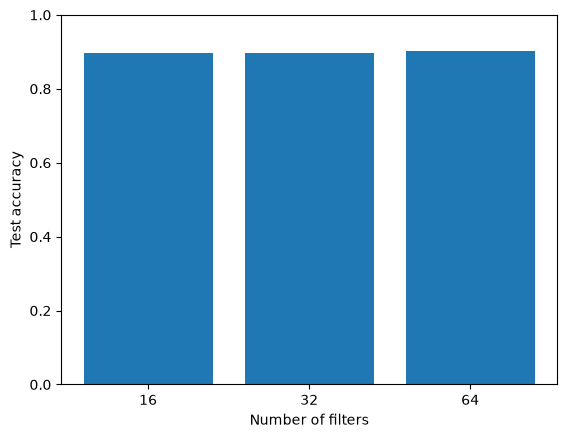

In [12]:
# A. Test Hyperparameters
filter_values = [16, 32, 64]
accuracies = []

for filters in filter_values:
    # Create a new model for each experiment
    model = Sequential()
    model.add(Conv2D(filters, (3, 3), activation="relu",
                     input_shape=(28, 28, 1)))
    model.add(Flatten())
    model.add(Dense(64, activation="relu"))
    model.add(Dense(10, activation="softmax"))

    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    model.fit(
        X_train, y_train_encoded,
        epochs=4,
        batch_size=128,
        verbose=0
    )

    loss, accuracy = model.evaluate(
        X_test, y_test_encoded, verbose=0
    )

    accuracies.append(accuracy)

    print("Filters:", filters)
    print("Test accuracy:", accuracy)
    print("Test loss:", loss)

# Compare the results
plt.bar(["16", "32", "64"], accuracies)
plt.xlabel("Number of filters")
plt.ylabel("Test accuracy")
plt.ylim(0, 1)
plt.show()

Dropout: 0.0
Test accuracy: 0.8974000215530396
Test loss: 0.28181150555610657
Dropout: 0.5
Test accuracy: 0.8883000016212463
Test loss: 0.3098200559616089


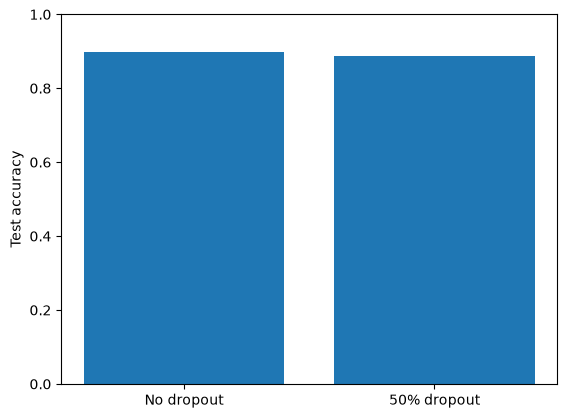

In [13]:
# B. Test presence or absence of regularization
from keras.layers import Dropout

dropout_values = [0.0, 0.5]
accuracies = []

for dropout in dropout_values:
    # Create a new model for each experiment
    model = Sequential()
    model.add(Conv2D(32, (3, 3), activation="relu",
                     input_shape=(28, 28, 1)))
    model.add(Flatten())
    model.add(Dense(64, activation="relu"))
    model.add(Dropout(dropout))
    model.add(Dense(10, activation="softmax"))

    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    model.fit(
        X_train, y_train_encoded,
        epochs=4,
        batch_size=128,
        verbose=0
    )

    loss, accuracy = model.evaluate(
        X_test, y_test_encoded, verbose=0
    )

    accuracies.append(accuracy)

    print("Dropout:", dropout)
    print("Test accuracy:", accuracy)
    print("Test loss:", loss)

# Compare the results
plt.bar(["No dropout", "50% dropout"], accuracies)
plt.ylabel("Test accuracy")
plt.ylim(0, 1)
plt.show()

Reflection: Report on the performance of the models you tested. Did any of the changes you made improve the model's performance? If so, which ones? What do you think contributed to these improvements? Finally, what combination of hyperparameters and regularization techniques yielded the best performance?

The best model used 64 filters without dropout, achieving 90.31% accuracy. More filters helped it learn patterns, while dropout reduced accuracy.

# 5. Training Final Model and Evaluation

In this section, you will train the final model using the best hyperparameters and regularization techniques you found in the previous section. You should:
- [ ] Compile the final model with the best hyperparameters and regularization techniques.
- [ ] Train the final model on the training set and evaluate it on the test set.
- [ ] Report the final model's performance on the test set, including accuracy and any other relevant metrics.

In [14]:
# Create the final model
model = Sequential()
model.add(Conv2D(64, (3, 3), activation="relu",
                 input_shape=(28, 28, 1)))
model.add(Flatten())
model.add(Dense(64, activation="relu"))
model.add(Dense(10, activation="softmax"))

# Compile the model
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Train the model
model.fit(
    X_train, y_train_encoded,
    epochs=4,
    batch_size=128
)

# Evaluate the model
final_loss, final_accuracy = model.evaluate(
    X_test, y_test_encoded
)

print("Final test accuracy:", final_accuracy)
print("Final test loss:", final_loss)

Epoch 1/4
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8456 - loss: 0.4432
Epoch 2/4
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8993 - loss: 0.2843
Epoch 3/4
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9126 - loss: 0.2423
Epoch 4/4
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9234 - loss: 0.2102
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8980 - loss: 0.2795
Final test accuracy: 0.8980000019073486
Final test loss: 0.27952516078948975


Reflection: How does the final model's performance compare to the baseline and the CNN model? What do you think contributed to the final model's performance? If you had time, what other experiments would you run to further improve the model's performance?

The final model achieved 89.80%, matching the first CNN and beating the baseline’s 80.49%. Convolution helped it learn image patterns. I would test different learning rates next.

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.
### Submission Parameters:
* Submission Due Date: `23:59 PM - 26/10/2025`
* The branch name for your repo should be: `assignment-1`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_1.ipynb)
    * The Lab 1 notebook (labs/lab_1.ipynb)
    * The Lab 2 notebook (labs/lab_2.ipynb)
    * The Lab 3 notebook (labs/lab_3.ipynb)
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/deep_learning/pull/<pr_id>`
* Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.
Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.
If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at `#cohort-7-help-ml`. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.